# Example of a Python Report and essential Python functions

In [ ]:
# %matplotlib widget 
# command to enable interactive mode in matplotlib figures

# Importation of useful libraries
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt

## I. Load of an image in the workspace

In [3]:
img0=cv.imread('Images/chro.png', cv.IMREAD_GRAYSCALE) # load of an image
img0=np.double(img0) # convert gray levels value to double type 

In [4]:
row=img0.shape[0] # number of rows in the image (height of the image)
col=img0.shape[1] # number of columns of the image (width)
# The shape attribute stores the dimensions of a numpy array

## II. Display of an image using imshow

imshow displays images of type "double" with a Look Up Table range adapted to the image range (a black (resp.
white) pixel corresponds to the minimum (resp. maximum) graylevel

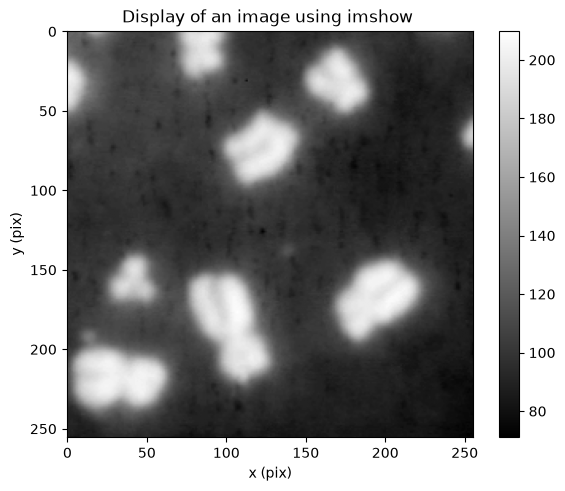

In [5]:
plt.figure(layout='compressed') # open a new graphical window.
plt.imshow(img0,'gray')
plt.colorbar() # choice of the Look Up Table (LUT) that will match the displayed color to the gray-level value of one pixel 
plt.title('Display of an image using imshow ') # displays a title 
plt.xlabel(r'x (pix)') # puts a label for abscissa 
plt.ylabel(r'y (pix)') # puts a label for ordinates. Note it is important to put the axis units
plt.show()

### Changing of the graylevel range

In [6]:
img1=2.5*img0

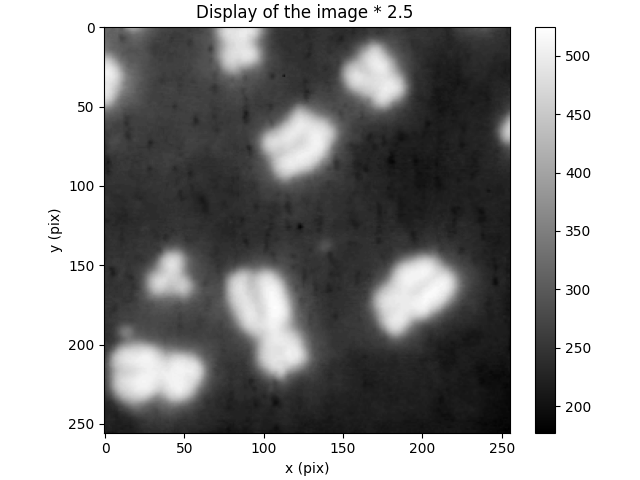

In [6]:
plt.figure(layout='compressed')
plt.imshow(img1,'gray')
plt.colorbar() 
plt.title('Display of the image * 2.5 ')
plt.xlabel(r'x (pix)')
plt.ylabel(r'y (pix)')
plt.show()

Adding units on axes for an image with its origin at the bottom-left

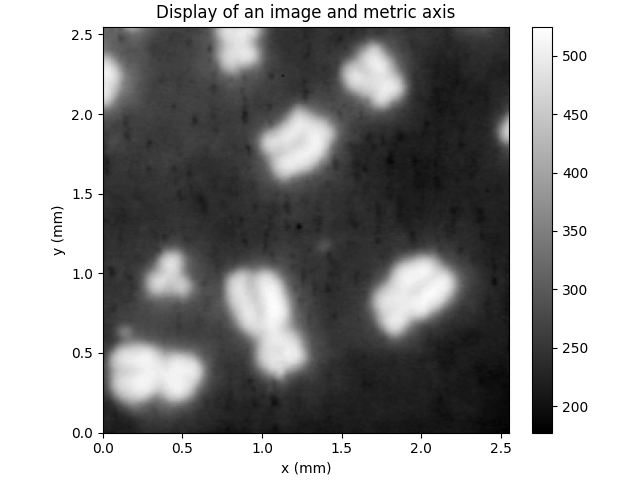

In [7]:
ps=10e-3; # pixel pitch (or pixel step) in mm
x_left=0            # x value on the left
x_right=(col-1)*ps  # x value on the right
y_bottom=0          # y value on the bottom
y_top=(row-1)*ps    # y value on the top

plt.figure(layout='compressed')

# display an image with specified axes (notice the extent field)
plt.imshow(img1,extent=[x_left,x_right,y_bottom,y_top],cmap='gray')

plt.colorbar() 
plt.title('Display of an image and metric axis')
plt.xlabel(r'x (mm)')
plt.ylabel(r'y (mm)')
plt.show()

## III Displaying an image as a 3D surface

In [8]:
xt = np.outer(np.linspace(x_left,x_right,col), np.ones(row))
yt = xt.copy().T # transpose
zt = img1



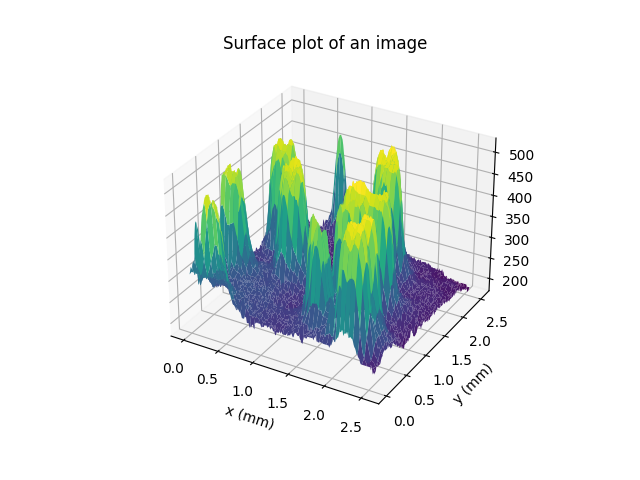

In [9]:
fig = plt.figure()
ax = plt.axes(projection='3d')

ax.plot_surface(xt, yt, zt,cmap='viridis', edgecolor='none')
plt.title('Surface plot of an image ')
plt.xlabel(r'x (mm)');plt.ylabel(r'y (mm)');
plt.show()


COMMENT : It is easier to distinguish the objects and the Gray Level variations around the contours objects.

## IV. Displaying a raw profile

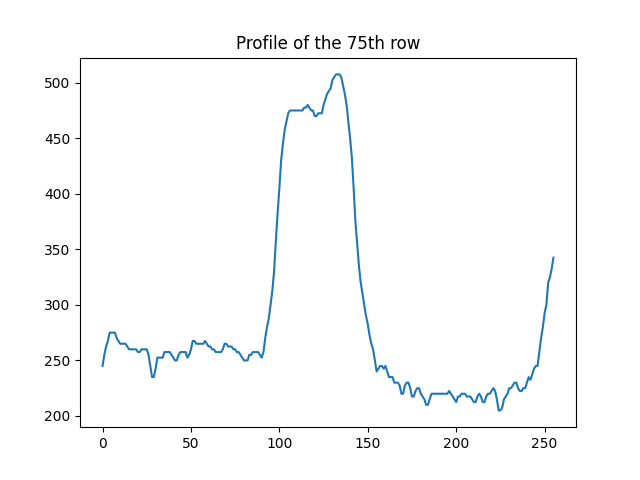

In [10]:
plt.figure()
prof=img1[74,:]
plt.plot(prof),plt.title('Profile of the 75th row')
plt.show()

## V. Python function example : Image multiplication

1/ computation of a symetrical image of img1.

2/ multiplication with img1 and normalization

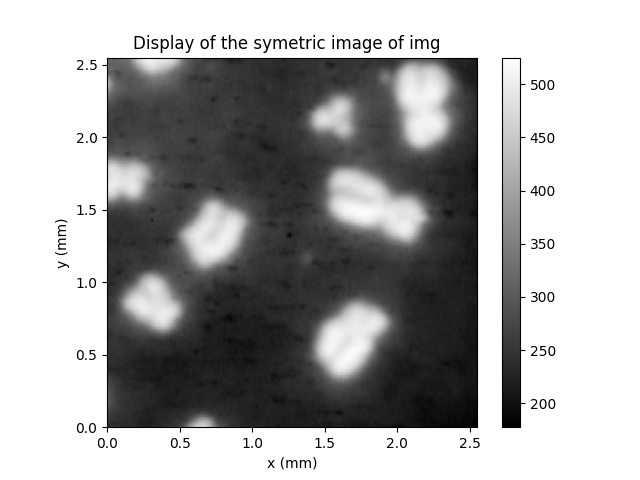

In [11]:
img1Sym=img1.transpose()
plt.figure()
plt.imshow(img1Sym,extent=[x_left,x_right,y_bottom,y_top],cmap='gray')
plt.colorbar() 
plt.title('Display of the symetric image of img  ')
plt.xlabel(r'x (mm)')
plt.ylabel(r'y (mm)')
plt.show()

In [12]:
image3=img1

def multiply_normalise(image1,image2):
    image3=image1*image2 # the global variable image3 is being shadowed by a new local variable image3
    mini=np.min(image3)
    maxi=np.max(image3)
    image3=(image3-mini)/(maxi-mini)
    return image3
    

img1_norm=multiply_normalise(img1,img1Sym)

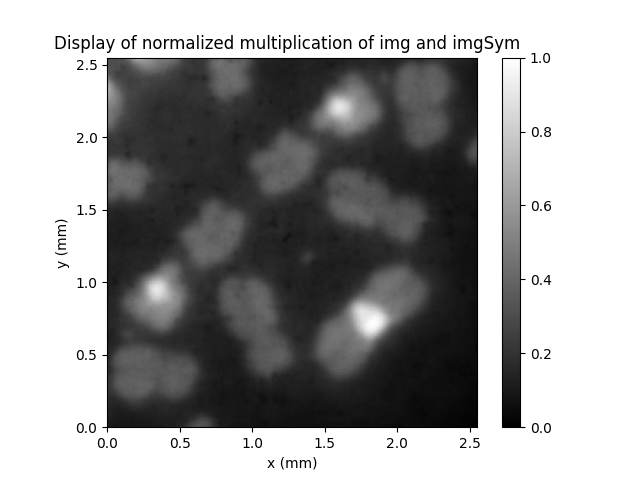

In [13]:
plt.figure()
plt.imshow(img1_norm,extent=[x_left,x_right,y_bottom,y_top],cmap='gray') 
plt.colorbar() 
plt.title('Display of normalized multiplication of img and imgSym  ')
plt.xlabel(r'x (mm)');plt.ylabel(r'y (mm)')
plt.show()

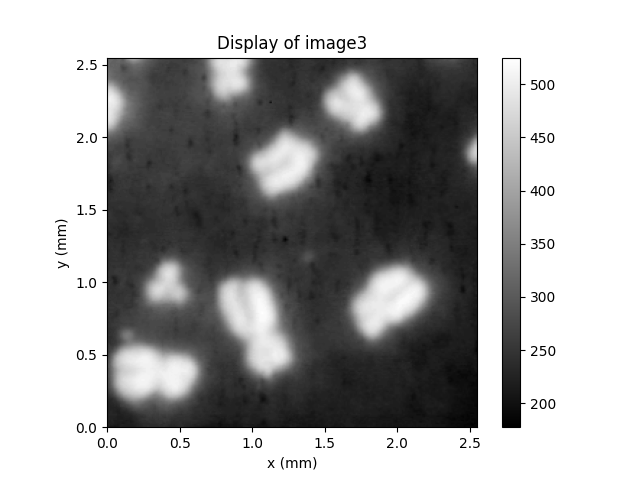

In [14]:
plt.figure()
plt.imshow(image3,extent=[x_left,x_right,y_bottom,y_top],cmap='gray') 
plt.colorbar() 
plt.title('Display of image3')
plt.xlabel(r'x (mm)');plt.ylabel(r'y (mm)')
plt.show()

## VII. Image window selection (Crop)

In [15]:
cropped_img1 = img1[136:202,164:229]


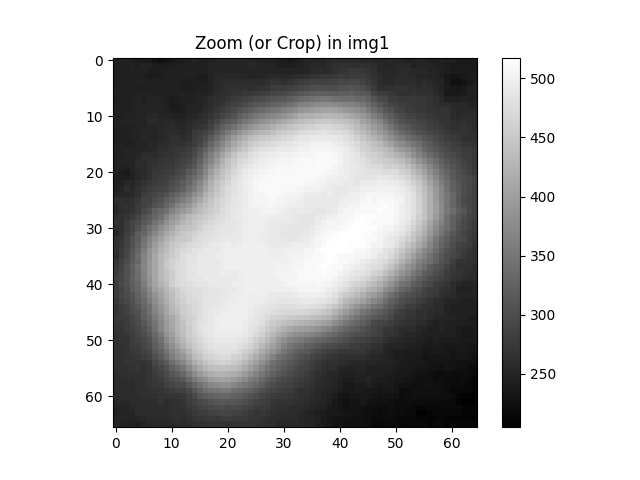

In [16]:
plt.figure()
plt.imshow(cropped_img1,cmap='gray')
plt.colorbar() 
plt.title('Zoom (or Crop) in img1 ')
plt.show()